# Model Selection and Clustering

This notebook encapsulates the complete pipeline for selecting the large language models (LLMs) to be subjected to study.

The process consists of:
1. **Data Collection**: Fetching model details from predefined Hugging Face collections.
2. **Filtering**: Applying a set of rules to ignore undesired models such as specialized, quantized, deprecated or base model versions, as well as specifically problematic model releases.
3. **Prioritization**: Choosing instruction-tuned models over their base versions.
4. **Clustering**: Grouping models into sizes (Tiny, Small, Standard, Mid-range, Large) using Jenks Natural Breaks.
5. **Selection**: Selecting the most recent or largest parameter model available within each category for each family.

### Setup & Imports
We import necessary libraries to handle API requests (`huggingface_hub`), data manipulation (`pandas`), and clustering (`jenkspy`).

In [1]:
import pandas as pd
import jenkspy
import re
import os
import json
from huggingface_hub import HfApi, get_collection, hf_hub_download
from transformers import AutoTokenizer, AutoConfig
from datetime import timedelta

/home/diogo/eco-evolution-of-llms/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### 1. Configuration and Filtering Rules
Here we define our constants and parameters for model collection. We set maximum limits, regex patterns to extract parameter sizes, and lists of keywords/types to ignore (e.g., GGUF, MoE, Vision models) ensuring we only capture standard text generation base or instruct models. Models that belong to a release but were published outside of its collection are listed in `EXTRA_MODELS`.

In [2]:
# Maximum parameter count in billions
MAX_PARAMS = 100

# Path to cache manual entries
MANUAL_CACHE_FILE = "manual_model_data.json"

def load_manual_cache():
    if os.path.exists(MANUAL_CACHE_FILE):
        with open(MANUAL_CACHE_FILE, "r") as f:
            return json.load(f)
    return {}

def save_manual_cache(cache):
    with open(MANUAL_CACHE_FILE, "w") as f:
        json.dump(cache, f, indent=4)

# Load existing cache
MANUAL_CACHE = load_manual_cache()

# Regex Patterns 
# Matches patterns like 7B, 13B, 70B
PARAM_PATTERN = re.compile(r'(\d+(?:\.\d+)?)\s*[Bb]', re.IGNORECASE)
# Matches patterns like 270M
M_PARAM_PATTERN = re.compile(r'(\d+(?:\.\d+)?)\s*m', re.IGNORECASE)
# Matches patterns like 30B-A3B (MoE architecture)
MOE_A_PATTERN = re.compile(r'(\d+(?:\.\d+)?)B-A(\d+(?:\.\d+)?)B', re.IGNORECASE)
# Matches patterns like 17B-128E (LLaMA 4 MoE architecture)
MOE_A_LLAMA_PATTERN = re.compile(r'(\d+(?:\.\d+)?)B-(\d+(?:\.\d+)?)E', re.IGNORECASE)
# Specifically for models that only list activated parameters (e.g. -A2.7B)
MOE_A_ONLY_PATTERN = re.compile(r'-A(\d+(?:\.\d+)?)[B|E]', re.IGNORECASE)
# Specifically for Gemma 4 Per-Layer Embeddings (e.g. -E4B)
GEMMA_E_PATTERN = re.compile(r'-E(\d+(?:\.\d+)?)[B|b]', re.IGNORECASE)
# Matches models that have "moe" in their name, case-insensitive
GENERIC_MOE_PATTERN = re.compile(r'moe', re.IGNORECASE)

# Instruction Suffixes
PRIORITIZE_SUFFIXES = ["-it", "-instruct", "-chat", "-instruction", "-hf"]

# Types to ignore
IGNORE_TYPES = {
    "audio-to-audio",
    "text-to-audio",
    "audio-text-to-audio",
    "text-to-image",
    "image-to-image",
    "image-text-to-image"
}

# Specific words to ignore in model names (case-insensitive)
IGNORE_WORDS = {
    # Quantized variants
    "gguf", "awq", "gptq", "quant", "quantized", "int4", "int8", "fp8", "4bit", "6bit", "8bit",
    # Specialized versions
    "special", "speciale", "vision", "image", "audio", "code", "coder", "math", "ocr", "guard",
    "pytorch", "keras", "flax", "cpp", "tflite", "mlx", "terminus", "exp", "shield", "assistant",
    "onnx", "plus",
    # Not instruction-tuned versions
    "base", "-pt",
    # Others
    "deprecated"
}

# Specific models to ignore by exact model ID
IGNORE_MODELS = {
    # Hugging Face base models that are not instruction-tuned, confusing the prioritization logic.
    "meta-llama/Llama-2-7b-hf",
    "meta-llama/Llama-2-13b-hf",
    # Unsupported 'Gemma4UnifiedForConditionalGeneration' architecture.
    # (Requires vLLM >= 0.23.0 and CUDA >= 13, the later was not available on the test environment)
    "google/gemma-4-12B",
    "google/gemma-4-12B-it",
    # Model architecture Phi3SmallForCausalLM no longer supported by vLLM > 0.9.2
    "microsoft/Phi-3-small-8k-instruct",
    "microsoft/Phi-3-small-128k-instruct",
    # Model architecture Phi4FlashForCausalLM no longer supported by vLLM > 0.10.2
    "microsoft/Phi-4-mini-flash-reasoning",
    # Stalls when loading for unknown reasons, likely incompatible with vLLM 0.19.1
    "microsoft/phi-1",
    "microsoft/phi-1_5",
    # Distributed with 8-bit (FP8) weights, although their names do not indicate it.
    # Their 16-bit versions are added through EXTRA_MODELS.
    "mistralai/Ministral-3-3B-Instruct-2512",
    "mistralai/Ministral-3-8B-Instruct-2512",
    "mistralai/Ministral-3-14B-Instruct-2512",
}

# Models added to a collection explicitly, because they were published outside of it
EXTRA_MODELS = {
    # 16-bit versions of the Ministral 3 instruct models (the collection only lists the FP8 ones)
    "mistralai/ministral-3": [
        "mistralai/Ministral-3-14B-Instruct-2512-BF16",
        "mistralai/Ministral-3-8B-Instruct-2512-BF16",
        "mistralai/Ministral-3-3B-Instruct-2512-BF16",
    ],
}

# Specific models to explicitly identify as MoE
MOE_MODELS = {
    "deepseek-ai/DeepSeek-V2",
    "deepseek-ai/DeepSeek-V2-Chat", 
    "deepseek-ai/DeepSeek-V2-Lite-Chat",
    "deepseek-ai/DeepSeek-V2.5",
    "deepseek-ai/DeepSeek-V2.5-1210",
    "deepseek-ai/DeepSeek-V3",
    "deepseek-ai/DeepSeek-V3-Base",
    "deepseek-ai/DeepSeek-V3.1-Base",
    "deepseek-ai/DeepSeek-V3.1",
    "deepseek-ai/DeepSeek-V3.2",
}

# Specific models to explicitly identify as Thinking/Reasoning
THINKING_MODELS = {"deepseek-ai/DeepSeek-R1-0528-Qwen3-8B"}

# Specific words to identify as Thinking/Reasoning (case-insensitive)
THINKING_WORDS = {"reason", "reasoning", "think", "thinking"}

### 2. Helper Functions
These functions parse model names to extract parameter sizes and query the Hugging Face API (`get_model_details`). During the API query, the model is checked against the ignoring rules before being accepted.

In [3]:
def format_to_billions(num):
    """Converts raw integer or float to 'X.XX' string."""
    if num is None or num == "N/A":
        return "N/A"
    try:
        return f"{float(num) / 1e9:.2f}"
    except (ValueError, TypeError):
        return str(num)


def prompt_for_missing_value(model_id, field_name):
    """Prompts the user to manually input a missing value for a model and caches it."""
    # Check cache first
    cache_key = f"{model_id}|{field_name}"
    if cache_key in MANUAL_CACHE:
        return MANUAL_CACHE[cache_key]

    while True:
        user_input = input(
            f"Enter {field_name} for {model_id}: "
        ).strip()
        if not user_input:
            print("Value is required. Please enter a number.")
            continue
        try:
            val = f"{float(user_input):.2f}"
            # Update cache and save
            MANUAL_CACHE[cache_key] = val
            save_manual_cache(MANUAL_CACHE)
            return val
        except ValueError:
            print("Invalid input. Please enter a numeric value.")


def extract_params_from_name(model_id):
    """
    Tries to find parameter count and density details in the model name.
    Returns (discovered_total, discovered_active, is_moe)
    """
    model_name_only = model_id.split("/")[-1]

    # 1. Check for explicit MoE Total and Active (e.g., 14B-A2.7B)
    moe_a_match = MOE_A_PATTERN.search(model_name_only)
    if moe_a_match:
        total = f"{float(moe_a_match.group(1)):.2f}"
        active = f"{float(moe_a_match.group(2)):.2f}"
        return total, active, True

    # 1b. Check for LLaMA 4 MoE pattern (e.g., 17B-128E)
    moe_a_llama_match = MOE_A_LLAMA_PATTERN.search(model_name_only)
    if moe_a_llama_match:
        active = f"{float(moe_a_llama_match.group(1)):.2f}"
        return "N/A", active, True

    # 2. Check for Active only pattern (e.g., -A2.7B)
    moe_a_only_match = MOE_A_ONLY_PATTERN.search(model_name_only)
    if moe_a_only_match:
        active = f"{float(moe_a_only_match.group(1)):.2f}"
        return "N/A", active, True

    # 3. Check for Gemma 4 'E' pattern (e.g., -E4B)
    gemma_e_match = GEMMA_E_PATTERN.search(model_name_only)
    if gemma_e_match:
        active = f"{float(gemma_e_match.group(1)):.2f}"
        # For Gemma 'E' models, total is often not specified in name
        return "N/A", active, True

    # 4. Fallback to generic parameter extraction
    is_moe = bool(GENERIC_MOE_PATTERN.search(model_name_only))

    match = PARAM_PATTERN.search(model_name_only)
    if match:
        try:
            val = f"{float(match.group(1)):.2f}"
            return val, val, is_moe
        except ValueError:
            pass
    else:
        alt_match = M_PARAM_PATTERN.search(model_name_only)
        if alt_match:
            try:
                val = f"{(float(alt_match.group(1))/1000):.2f}"
                return val, val, is_moe
            except ValueError:
                pass

    return "N/A", "N/A", is_moe


def check_is_thinking(model_id):
    """
    Checks if a model is a reasoning/thinking model based on:
    1. Hardcoded THINKING_MODELS list
    2. Name containing thinking words
    3. Chat template containing thinking tags
    """
    if model_id in THINKING_MODELS:
        return True

    model_id_lower = model_id.lower()
    if any(word in model_id_lower for word in THINKING_WORDS):
        return True

    try:
        tokenizer = AutoTokenizer.from_pretrained(model_id, fix_mistral_regex=True)
        # Check for the presence of 'think' tags in the default chat template
        if tokenizer.chat_template:
            template = tokenizer.chat_template
            if isinstance(template, list):
                template = str(template)
            thinking_tags = ["<think>", "<reasoning>", "<|think|>", "<|channel>thought"]
            if any(tag in template for tag in thinking_tags):
                return True
    except Exception:
        pass

    return False


def check_supports_enable_thinking(model_id: str) -> bool:
    """
    Checks if a model explicitly supports the 'enable_thinking' parameter
    by inspecting its chat template and tokenizer configuration.
    """
    # 1. Check via AutoTokenizer's chat template
    try:
        tokenizer = AutoTokenizer.from_pretrained(model_id, trust_remote_code=True, fix_mistral_regex=True)
        if tokenizer.chat_template:
            template = str(tokenizer.chat_template)
            # Jinja templates that support toggles will explicitly reference the variable name
            if "enable_thinking" in template:
                return True
    except Exception:
        pass

    # 2. Deep inspection of raw tokenizer_config.json for kwargs / template definition
    try:
        config_path = hf_hub_download(
            repo_id=model_id, filename="tokenizer_config.json"
        )
        with open(config_path, "r", encoding="utf-8") as f:
            config_data = json.load(f)

        # Check stringified config for references to enable_thinking
        # (Handles cases where it's in clean_up_tokenization_spaces, default kwargs, or the Jinja string)
        config_str = json.dumps(config_data)
        if "enable_thinking" in config_str:
            return True

    except Exception:
        pass

    return False


def get_max_model_length(model_id):
    """
    Attempts to fetch the maximum natively supported context length from the model's config.
    """
    try:
        config = AutoConfig.from_pretrained(model_id, trust_remote_code=True, fix_mistral_regex=True)

        # Some multimodal models (like Gemma 3) store their text sequence length inside a text_config
        target_config = config.text_config if hasattr(config, "text_config") else config

        # Check standard config attributes used by different architectures for max context length
        if hasattr(target_config, "max_position_embeddings"):
            return target_config.max_position_embeddings
        elif hasattr(target_config, "n_positions"):
            return target_config.n_positions
        elif hasattr(target_config, "seq_length"):
            return target_config.seq_length
        elif hasattr(target_config, "max_sequence_length"):
            return target_config.max_sequence_length

    except Exception:
        pass

    return prompt_for_missing_value(model_id, "Maximum Context Length")


def get_total_parameters_from_config(model_id):
    """
    Attempts to calculate the total number of parameters accurately by instantiating an
    empty model from the config and extracting the parameter count directly.
    """
    try:
        from transformers import AutoModelForCausalLM
        import accelerate

        config = AutoConfig.from_pretrained(model_id, trust_remote_code=True, fix_mistral_regex=True)
        # Initialize an empty model using accelerate to avoid downloading weights
        with accelerate.init_empty_weights():
            model = AutoModelForCausalLM.from_config(config, trust_remote_code=True)

        return format_to_billions(model.num_parameters())
    except Exception:
        return "N/A"


def get_total_parameters_from_safetensors(model_id, safetensors):
    """
    Reads the total number of parameters from the safetensors metadata of the Hub, as the sum
    of the parameters of each data type. The 'total' field is only used when that breakdown is
    missing, since for some repositories it does not match the weights (it counts tied input
    and output embeddings twice).
    """
    parameters = safetensors["parameters"] if "parameters" in safetensors else None
    total = safetensors["total"] if "total" in safetensors else None

    if parameters:
        counted = sum(parameters.values())
        if total and abs(total - counted) / counted > 0.001:
            print(
                f"  [!] {model_id}: safetensors total ({total}) differs from the sum of its "
                f"per-type counts ({counted}). Using the sum."
            )
        return format_to_billions(counted)
    if total:
        return format_to_billions(total)
    if "total_size" in safetensors:
        return format_to_billions(safetensors["total_size"])
    return "N/A"


def get_model_details(api, model_id):
    """Fetches details and returns (model_dict, status_string)."""
    try:
        # 1. Filter out by model id if it's in the ignore list
        if model_id in IGNORE_MODELS:
            return None, "Manually ignored"

        # 2. Filter out by ignored words in the name
        model_id_lower = model_id.lower()
        for word in IGNORE_WORDS:
            if word.lower() in model_id_lower:
                return None, f"Ignored word '{word}'"

        # Fetch model info only after local name checks pass
        info = api.model_info(model_id)

        # 3. Filter out ignored model types
        if info.pipeline_tag and info.pipeline_tag.lower() in IGNORE_TYPES:
            return None, f"Ignored type '{info.pipeline_tag}'"

        if info.tags:
            for tag in info.tags:
                if tag.lower() in IGNORE_TYPES:
                    return None, f"Ignored tag '{tag}'"

        # 4. Extract Release Date
        release_date = (
            info.created_at.strftime("%Y-%m-%d") if info.created_at else "N/A"
        )

        # 5. Extract Parameter Counts (Metadata -> Config -> Name Fallback -> Manual Prompt)
        total_params = "N/A"
        activated_params = "N/A"
        is_moe = False

        # A. Check safetensors metadata first for total params (Source of Truth)
        if info.safetensors:
            total_params = get_total_parameters_from_safetensors(model_id, info.safetensors)

        # B. Check config for total params
        if total_params == "N/A":
            # Attempt to use AutoConfig and empty model trick
            total_params = get_total_parameters_from_config(model_id)

        # C. Discover counts from name as fallback
        n_total, n_active, n_is_moe = extract_params_from_name(model_id)

        # D. MoE Identification logic
        is_moe = n_is_moe
        if info.tags and any("moe" in tag.lower() for tag in info.tags):
            is_moe = True
        if model_id in MOE_MODELS:
            is_moe = True

        # E. Parameters Assignment logic
        # If metadata and config are both missing total, use name's total
        if total_params == "N/A":
            total_params = n_total

        # If still N/A, prompt manually
        if total_params == "N/A":
            total_params = prompt_for_missing_value(model_id, "Total Parameters (in billions)")

        if is_moe:
            # For MoE, use 'active' from name if found, else fallback to N/A
            activated_params = n_active if n_active != "N/A" else "N/A"
            if activated_params == "N/A":
                # Only prompt if it's definitely MoE and we don't have active params
                activated_params = prompt_for_missing_value(
                    model_id, "Activated Parameters (in billions)"
                )
        else:
            # For dense, both are the same
            activated_params = total_params

        if total_params != "N/A" and float(total_params) > MAX_PARAMS:
            return None, f"Exceeds max params ({total_params}B > {MAX_PARAMS}B)"

        # 6. Determine Thinking Mode
        is_thinking = check_is_thinking(model_id)

        # 7. Check if model supports 'enable_thinking' parameter
        supports_enable_thinking = check_supports_enable_thinking(model_id)

        # 8. Extract Max Context Length
        max_model_length = get_max_model_length(model_id)

        return {
            "model": model_id,
            "total_parameters": total_params,
            "activated_parameters": activated_params,
            "max_model_length": max_model_length,
            "is_moe": is_moe,
            "is_thinking": is_thinking or supports_enable_thinking,
            "is_instruct": not is_thinking or supports_enable_thinking,
            "supports_enable_thinking": supports_enable_thinking,
            "release_date": release_date,
        }, "Accepted"
    except Exception as e:
        return None, f"API Error: {e}"

### 3. Fetching Data from Hugging Face
We iterate over the list of chosen collections, fetch the models in each collection, together with the ones listed for it in `EXTRA_MODELS`, and apply our filtering logic to compile a list of viable models.

In [4]:
COLLECTIONS = [
    # Original Qwen collection is ignored since its models are not natively supported by Hugging Face Transformers,
    # needing to run remote code that fails since it is not compatible with current package versions.
    # The Qwen 1.5 collection contains re-released model weights from the original Qwen collection,
    # but in a format that is natively supported.
    "Qwen/qwen15",
    "Qwen/qwen2",
    "Qwen/qwen25",
    "Qwen/qwen3",
    "Qwen/qwen35",
    "Qwen/qwen36",
    # Meta's Llama
    "meta-llama/llama-2-family",
    "meta-llama/meta-llama-3",
    "meta-llama/llama-31",
    "meta-llama/llama-32",
    "meta-llama/llama-33",
    "meta-llama/llama-4",
    # DeepSeek AI's DeepSeek
    "deepseek-ai/deepseek-llm",
    "deepseek-ai/deepseek-v2",
    "deepseek-ai/deepseek-v25",
    "deepseek-ai/deepseek-r1",
    "deepseek-ai/deepseek-v3",
    "deepseek-ai/deepseek-v31",
    "deepseek-ai/deepseek-v32",
    "deepseek-ai/deepseek-v4",
    # Google's Gemma
    "google/gemma-release",
    "google/gemma-2-release",
    "google/gemma-3-release",
    "google/gemma-3n",
    "google/gemma-4",
    # Mistral AI's Ministral
    "mistralai/ministral-3",
    "mistralai/mistral-large-3",
    "mistralai/mistral-medium-35",
    "mistralai/mistral-small-4",
    # Microsoft's Phi
    "microsoft/phi-1",
    "microsoft/phi-3",
    "microsoft/phi-4",
]

api = HfApi()
rows = []

for col_id in COLLECTIONS:
    print(f"\n📦 Collection: {col_id}")
    try:
        collection = get_collection(col_id)
        model_ids = [item.item_id for item in collection.items if item.item_type == "model"]
        model_ids += EXTRA_MODELS.get(col_id, [])
        for model_id in model_ids:
            details, reason = get_model_details(api, model_id)

            if details:
                details["collection"] = col_id
                details["collection_name"] = collection.title
                rows.append(details)
                print(f"  ✓ {model_id}")
            else:
                print(f"  ✗ {model_id} (Reason: {reason})")
    except Exception as e:
        print(f"  [!] Collection Error: {e}")


📦 Collection: Qwen/qwen15
  ✗ Qwen/Qwen1.5-110B-Chat (Reason: Exceeds max params (111.21B > 100B))
  ✗ Qwen/Qwen1.5-110B (Reason: Exceeds max params (111.21B > 100B))
  ✓ Qwen/Qwen1.5-32B
  ✓ Qwen/Qwen1.5-32B-Chat
  ✓ Qwen/Qwen1.5-72B-Chat
  ✓ Qwen/Qwen1.5-72B
  ✓ Qwen/Qwen1.5-MoE-A2.7B
  ✓ Qwen/Qwen1.5-MoE-A2.7B-Chat
  ✓ Qwen/Qwen1.5-4B
  ✓ Qwen/Qwen1.5-4B-Chat
  ✗ Qwen/Qwen1.5-32B-Chat-GPTQ-Int4 (Reason: Ignored word 'gptq')
  ✗ Qwen/Qwen1.5-32B-Chat-GGUF (Reason: Ignored word 'gguf')
  ✗ Qwen/Qwen1.5-32B-Chat-AWQ (Reason: Ignored word 'awq')
  ✓ Qwen/Qwen1.5-0.5B
  ✓ Qwen/Qwen1.5-0.5B-Chat
  ✓ Qwen/Qwen1.5-1.8B
  ✓ Qwen/Qwen1.5-7B
  ✓ Qwen/Qwen1.5-14B
  ✓ Qwen/Qwen1.5-14B-Chat
  ✗ Qwen/Qwen1.5-0.5B-Chat-GPTQ-Int4 (Reason: Ignored word 'gptq')
  ✗ Qwen/Qwen1.5-7B-Chat-GPTQ-Int4 (Reason: Ignored word 'gptq')
  ✓ Qwen/Qwen1.5-1.8B-Chat
  ✓ Qwen/Qwen1.5-7B-Chat
  ✗ Qwen/Qwen1.5-0.5B-Chat-GPTQ-Int8 (Reason: Ignored word 'gptq')
  ✗ Qwen/Qwen1.5-14B-Chat-GPTQ-Int4 (Reason: Ignored word '

[transformers] Unrecognized keys in `rope_parameters` for 'rope_type'='yarn': {'attn_factor'}
[transformers] Unrecognized keys in `rope_parameters` for 'rope_type'='yarn': {'attn_factor'}


  ✓ deepseek-ai/DeepSeek-R1-0528-Qwen3-8B

📦 Collection: deepseek-ai/deepseek-v3
  ✗ deepseek-ai/DeepSeek-V3-Base (Reason: Ignored word 'base')
  ✗ deepseek-ai/DeepSeek-V3 (Reason: Exceeds max params (684.53B > 100B))
  ✗ deepseek-ai/DeepSeek-V3-0324 (Reason: Exceeds max params (684.53B > 100B))

📦 Collection: deepseek-ai/deepseek-v31
  ✗ deepseek-ai/DeepSeek-V3.1-Base (Reason: Ignored word 'base')
  ✗ deepseek-ai/DeepSeek-V3.1 (Reason: Exceeds max params (684.53B > 100B))
  ✗ deepseek-ai/DeepSeek-V3.1-Terminus (Reason: Ignored word 'terminus')

📦 Collection: deepseek-ai/deepseek-v32
  ✗ deepseek-ai/DeepSeek-V3.2-Exp (Reason: Ignored word 'exp')
  ✗ deepseek-ai/DeepSeek-V3.2-Exp-Base (Reason: Ignored word 'exp')
  ✗ deepseek-ai/DeepSeek-V3.2 (Reason: Exceeds max params (685.36B > 100B))
  ✗ deepseek-ai/DeepSeek-V3.2-Speciale (Reason: Ignored word 'special')

📦 Collection: deepseek-ai/deepseek-v4
  ✗ deepseek-ai/DeepSeek-V4-Flash-Base (Reason: Ignored word 'base')
  ✗ deepseek-ai/DeepSe

[transformers] You are using a model of type `diffusion_gemma` to instantiate a model of type ``. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.
[transformers] You are using a model of type `diffusion_gemma` to instantiate a model of type ``. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


  ✓ google/diffusiongemma-26B-A4B-it

📦 Collection: mistralai/ministral-3
  ✗ mistralai/Ministral-3-14B-Instruct-2512 (Reason: Manually ignored)
  ✗ mistralai/Ministral-3-8B-Instruct-2512 (Reason: Manually ignored)
  ✗ mistralai/Ministral-3-3B-Instruct-2512 (Reason: Manually ignored)
  ✓ mistralai/Ministral-3-14B-Reasoning-2512
  ✓ mistralai/Ministral-3-8B-Reasoning-2512
  [!] mistralai/Ministral-3-3B-Reasoning-2512: safetensors total (4251743232) differs from the sum of its per-type counts (3849090048). Using the sum.
  ✓ mistralai/Ministral-3-3B-Reasoning-2512
  ✗ mistralai/Ministral-3-14B-Base-2512 (Reason: Ignored word 'base')
  ✗ mistralai/Ministral-3-8B-Base-2512 (Reason: Ignored word 'base')
  ✗ mistralai/Ministral-3-3B-Base-2512 (Reason: Ignored word 'base')
  ✓ mistralai/Ministral-3-14B-Instruct-2512-BF16
  ✓ mistralai/Ministral-3-8B-Instruct-2512-BF16
  [!] mistralai/Ministral-3-3B-Instruct-2512-BF16: safetensors total (4251743232) differs from the sum of its per-type counts 

...

  ✓ microsoft/Phi-3.5-mini-instruct


[transformers] Unrecognized keys in `rope_parameters` for 'rope_type'='longrope': {'long_mscale', 'short_mscale'}
[transformers] Unrecognized keys in `rope_parameters` for 'rope_type'='longrope': {'long_mscale', 'short_mscale'}
[transformers] Unrecognized keys in `rope_parameters` for 'rope_type'='longrope': {'long_mscale', 'short_mscale'}


  ✓ microsoft/Phi-3.5-MoE-instruct
  ✗ microsoft/Phi-3.5-vision-instruct (Reason: Ignored word 'vision')
  ✓ microsoft/Phi-3-mini-4k-instruct
  ✓ microsoft/Phi-3-mini-128k-instruct
  ✗ microsoft/Phi-3-small-8k-instruct (Reason: Manually ignored)
  ✗ microsoft/Phi-3-small-128k-instruct (Reason: Manually ignored)
  ✓ microsoft/Phi-3-medium-4k-instruct


[transformers] Missing validation function in 'RotaryEmbeddingConfigMixin' for 'rope_type'='su'
[transformers] Missing validation function in 'RotaryEmbeddingConfigMixin' for 'rope_type'='su'


  ✓ microsoft/Phi-3-medium-128k-instruct
  ✗ microsoft/Phi-3-vision-128k-instruct (Reason: Ignored word 'vision')
  ✗ microsoft/Phi-3.5-mini-instruct-onnx (Reason: Ignored word 'onnx')
  ✗ microsoft/Phi-3.5-vision-instruct-onnx (Reason: Ignored word 'onnx')
  ✗ microsoft/Phi-3-mini-4k-instruct-onnx (Reason: Ignored word 'onnx')
  ✗ microsoft/Phi-3-mini-4k-instruct-onnx-web (Reason: Ignored word 'onnx')
  ✗ microsoft/Phi-3-mini-128k-instruct-onnx (Reason: Ignored word 'onnx')
  ✗ microsoft/Phi-3-small-8k-instruct-onnx-cuda (Reason: Ignored word 'onnx')
  ✗ microsoft/Phi-3-medium-4k-instruct-onnx-cpu (Reason: Ignored word 'onnx')
  ✗ microsoft/Phi-3-medium-4k-instruct-onnx-cuda (Reason: Ignored word 'onnx')
  ✗ microsoft/Phi-3-medium-4k-instruct-onnx-directml (Reason: Ignored word 'onnx')
  ✗ microsoft/Phi-3-medium-128k-instruct-onnx-cpu (Reason: Ignored word 'onnx')
  ✗ microsoft/Phi-3-medium-128k-instruct-onnx-cuda (Reason: Ignored word 'onnx')
  ✗ microsoft/Phi-3-medium-128k-instruct-

### 4. Post-Processing: Prioritize Instruction-Tuned Models
If a base model and its instruction-tuned variant (e.g., `-it`, `-chat`) both exist in the parsed list, we remove the base model and keep only the instruction-tuned version.

In [5]:
model_map = {r["model"]: r for r in rows}
to_remove = {}

for model_id in model_map.keys():
    for s in PRIORITIZE_SUFFIXES:
        s_lower = s.lower()
        model_id_lower = model_id.lower()
        if model_id_lower.endswith(s_lower):
            base_name = model_id[:-len(s)]
            if base_name in model_map:
                to_remove[base_name] = model_id

print("\n🔄 Prioritizing Models:")
if not to_remove:
    print("  - No base models needed removal.")
else:
    for base, tuned in to_remove.items():
        print(f"  ✗ Removed {base}")
        print(f"  ↳ ✓ Kept {tuned}")

final_rows = [r for r in rows if r["model"] not in to_remove]



🔄 Prioritizing Models:
  ✗ Removed Qwen/Qwen1.5-32B
  ↳ ✓ Kept Qwen/Qwen1.5-32B-Chat
  ✗ Removed Qwen/Qwen1.5-72B
  ↳ ✓ Kept Qwen/Qwen1.5-72B-Chat
  ✗ Removed Qwen/Qwen1.5-MoE-A2.7B
  ↳ ✓ Kept Qwen/Qwen1.5-MoE-A2.7B-Chat
  ✗ Removed Qwen/Qwen1.5-4B
  ↳ ✓ Kept Qwen/Qwen1.5-4B-Chat
  ✗ Removed Qwen/Qwen1.5-0.5B
  ↳ ✓ Kept Qwen/Qwen1.5-0.5B-Chat
  ✗ Removed Qwen/Qwen1.5-14B
  ↳ ✓ Kept Qwen/Qwen1.5-14B-Chat
  ✗ Removed Qwen/Qwen1.5-1.8B
  ↳ ✓ Kept Qwen/Qwen1.5-1.8B-Chat
  ✗ Removed Qwen/Qwen1.5-7B
  ↳ ✓ Kept Qwen/Qwen1.5-7B-Chat
  ✗ Removed Qwen/Qwen2-72B
  ↳ ✓ Kept Qwen/Qwen2-72B-Instruct
  ✗ Removed Qwen/Qwen2-7B
  ↳ ✓ Kept Qwen/Qwen2-7B-Instruct
  ✗ Removed Qwen/Qwen2-57B-A14B
  ↳ ✓ Kept Qwen/Qwen2-57B-A14B-Instruct
  ✗ Removed Qwen/Qwen2-1.5B
  ↳ ✓ Kept Qwen/Qwen2-1.5B-Instruct
  ✗ Removed Qwen/Qwen2-0.5B
  ↳ ✓ Kept Qwen/Qwen2-0.5B-Instruct
  ✗ Removed Qwen/Qwen2.5-0.5B
  ↳ ✓ Kept Qwen/Qwen2.5-0.5B-Instruct
  ✗ Removed Qwen/Qwen2.5-1.5B
  ↳ ✓ Kept Qwen/Qwen2.5-1.5B-Instruct
  ✗ Remove

### 5. Build DataFrame
We ingest our final collected row definitions into a structured Pandas DataFrame to facilitate easier data processing.

In [6]:
df = pd.DataFrame(final_rows)
df['total_parameters'] = pd.to_numeric(df['total_parameters'], errors='coerce')
df = df.dropna(subset=['total_parameters']).copy()
df.to_csv("models.csv", index=False)

### 6. Calculate Natural Breaks with Jenks
To properly categorize models into distinct size categories without arbitrary thresholds, we use Jenks Natural Breaks optimization. This seeks to minimize each class's average deviation from the class mean, while maximizing each class's deviation from the means of the other groups.

In [7]:
from pathlib import Path

chart_dir = Path("charts")
chart_dir.mkdir(exist_ok=True)

df = pd.read_csv("models.csv")
column_data = df['total_parameters']
values = column_data.dropna().astype(float).to_list()
breaks = jenkspy.jenks_breaks(values, n_classes=5)
breaks

[np.float64(0.27),
 np.float64(5.12),
 np.float64(9.65),
 np.float64(15.71),
 np.float64(41.87),
 np.float64(72.71)]

### 7. Assign Labels
Apply the calculated bins to split our dataframe into 'Tiny/Mobile', 'Small/Edge', 'Standard/Desktop', 'Mid-range/Server' and 'Large/Enterprise' tiers.

In [8]:
# Define categories based on breaks
df["category"] = pd.cut(
    column_data,
    bins=breaks,
    labels=[
        "Tiny/Mobile",
        "Small/Edge",
        "Standard/Desktop",
        "Mid-range/Server",
        "Large/Enterprise",
    ],
    ordered=False,
    include_lowest=True,
)

# Define order of columns
df = df[
    [
        "collection",
        "collection_name",
        "model",
        "total_parameters",
        "activated_parameters",
        "max_model_length",
        "is_moe",
        "is_thinking",
        "is_instruct",
        "supports_enable_thinking",
        "release_date",
        "category",
    ]
]

print("Total models after categorization:", len(df))

Total models after categorization: 96


### 8. Visualization of model distribution over time by size category

Across all five size categories, there is a consistent presence of both older and newly released models (late 2023 to early 2026).

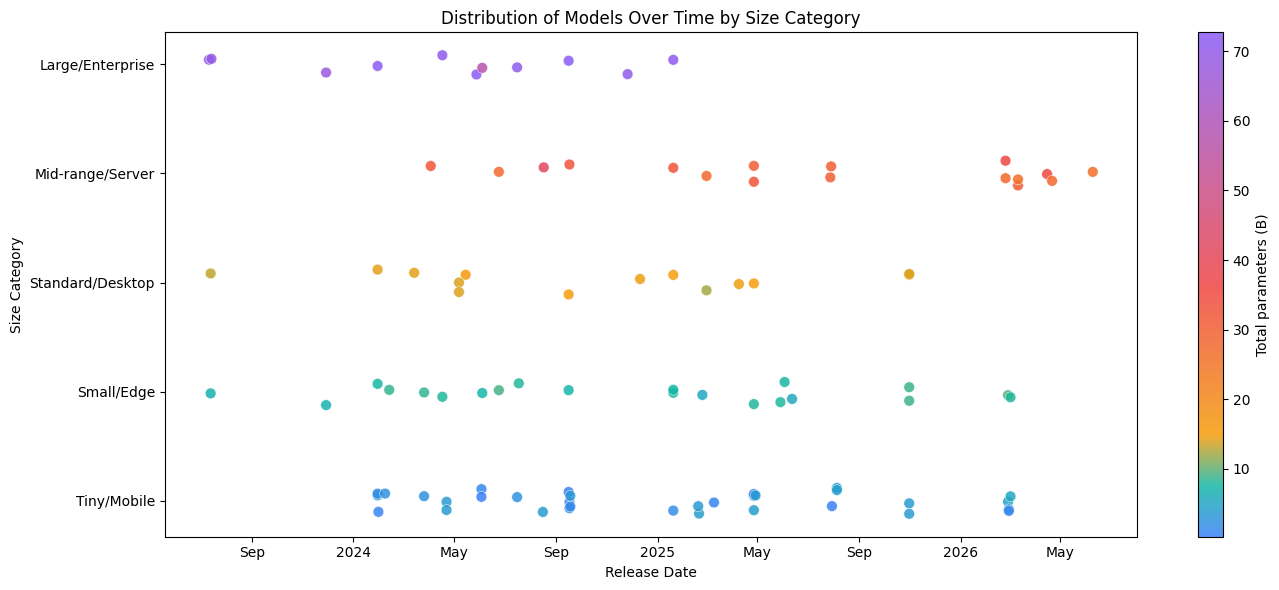

In [9]:
import numpy as np
from matplotlib.colors import LinearSegmentedColormap
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

custom_cmap = LinearSegmentedColormap.from_list(
    "size_gradient",
    [
        (0, "#3B82F6"),
        (0.1, "#14B8A6"),
        (0.2, "#F59E0B"),
        (0.5, "#EF4444"),
        (1, "#8B5CF6"),
    ],
)

plot_df = df.copy()
plot_df["release_date"] = pd.to_datetime(plot_df["release_date"], errors="coerce")
plot_df = plot_df.dropna(subset=["release_date", "category"]).copy()

cat_order = [
    "Tiny/Mobile",
    "Small/Edge",
    "Standard/Desktop",
    "Mid-range/Server",
    "Large/Enterprise",
]
plot_df["category"] = pd.Categorical(
    plot_df["category"], categories=cat_order, ordered=True
)
plot_df = plot_df.dropna(subset=["category"])

y_codes = plot_df["category"].cat.codes.to_numpy()
rng = np.random.default_rng(42)
jitter = (rng.random(len(y_codes)) - 0.5) * 0.25
y_jitter = y_codes + jitter

fig, ax = plt.subplots(figsize=(14, 6))
sc = ax.scatter(
    plot_df["release_date"],
    y_jitter,
    c=plot_df["total_parameters"],
    cmap=custom_cmap,
    s=60,
    alpha=0.85,
    edgecolors="w",
    linewidth=0.4,
)

ax.set_yticks(range(len(cat_order)))
ax.set_yticklabels(cat_order)
ax.set_xlabel("Release Date")
ax.set_ylabel("Size Category")
ax.set_title("Distribution of Models Over Time by Size Category")

locator = mdates.AutoDateLocator()
formatter = mdates.ConciseDateFormatter(locator)
ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(formatter)

cbar = fig.colorbar(sc, ax=ax)
cbar.set_label("Total parameters (B)")

plt.tight_layout()
fig.savefig(chart_dir / "distribution-over-time.svg", format="svg", bbox_inches="tight")
plt.show()

### 9. Filter Out Size Categories

Keep only models whose size category is compatible with local hardware limits. For this study, an NVIDIA L40S GPU with ~45GB or VRAM is used, which can handle loading models of up to 20B total parameters in full BF16 precision. This limits our study to the size categories bellow Mid-range/Server.

In [10]:
df = df[~df["category"].isin(["Mid-range/Server", "Large/Enterprise"])].copy()
print("Remaining models:", len(df))

Remaining models: 68


### 10. Filter Selection per Family, Size Category and Design

To refine the experimental selection, we apply the following rules within each combination of **size category**, **collection (i.e., model release)**, **architecture type (Dense vs. MoE)** and **thinking mode**:

1. **Size Priority**: If multiple models exist, select the one with the largest parameter count.
2. **Recency Priority**: If there is a tie in parameter count, select the most recently released model.

The resulting dataset is then saved to a CSV file.

In [11]:
df["total_parameters"] = pd.to_numeric(df["total_parameters"], errors="coerce")
df["activated_parameters"] = pd.to_numeric(df["activated_parameters"], errors="coerce")
df["release_date"] = pd.to_datetime(df["release_date"], errors="coerce")

filtered_df = (
    df.sort_values(
        by=["category", "collection", "total_parameters", "release_date"],
        ascending=[True, True, False, False],
    )
    .drop_duplicates(
        subset=["category", "collection", "is_moe", "is_thinking"],
        keep="first",
    )
    .copy()
)

before_split_filtered_df = filtered_df.copy()

# For models that support 'enable_thinking' (aka are both thinking and instruct),
# we want to create two variants to test both modes in the evaluation.
thinking_instruct_mask = filtered_df['is_thinking'] & filtered_df['is_instruct']
filtered_df_rest = filtered_df[~thinking_instruct_mask].copy()
filtered_df_to_duplicate = filtered_df[thinking_instruct_mask].copy()

variant_a = filtered_df_to_duplicate.copy()
variant_a["model"] = variant_a["model"] + " (Thinking Mode)"
variant_a["is_thinking"] = True
variant_a["is_instruct"] = False

variant_b = filtered_df_to_duplicate.copy()
variant_b["model"] = variant_b["model"] + " (Instruct Mode)"
variant_b["is_thinking"] = False
variant_b["is_instruct"] = True

filtered_df = pd.concat([filtered_df_rest, variant_a, variant_b], ignore_index=True)

filtered_df.sort_values(
    by=["category", "release_date"], ascending=[True, True], inplace=True
)
filtered_df.reset_index(drop=True, inplace=True)
filtered_df.to_csv("selected_models.csv", index=False)

print("Total model runs after filtering and prioritization:", len(filtered_df))

Total model runs after filtering and prioritization: 53


### 11. Final Statistics
Displaying the number of models successfully selected per category.

In [12]:
before_split_filtered_df.groupby("category").size().reindex(
    [
        "Tiny/Mobile",
        "Small/Edge",
        "Standard/Desktop",
    ]
)

category
Tiny/Mobile         17
Small/Edge          17
Standard/Desktop    13
dtype: int64

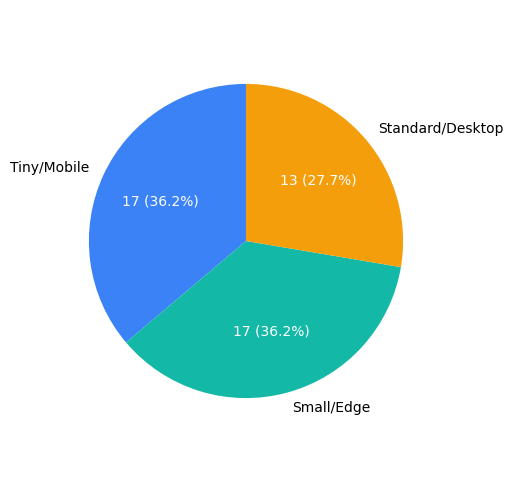

In [13]:
category_counts = before_split_filtered_df.groupby("category").size().reindex(
    [
        "Tiny/Mobile",
        "Small/Edge",
        "Standard/Desktop",
    ]
)

fig, ax = plt.subplots(figsize=(6, 6))
wedges, labels, autotexts = ax.pie(
    category_counts,
    labels=[
        "Tiny/Mobile",
        "Small/Edge",
        "Standard/Desktop",
    ],
    autopct=lambda pct: f"{int(round(pct / 100 * category_counts.sum()))} ({pct:.1f}%)",
    startangle=90,
    colors=["#3B82F6", "#14B8A6", "#F59E0B"],
    radius=0.85
)
ax.set_aspect("equal", adjustable="box")
plt.setp(autotexts, color="white")
fig.savefig(chart_dir / "pie-size-category.svg", format="svg", bbox_inches="tight")

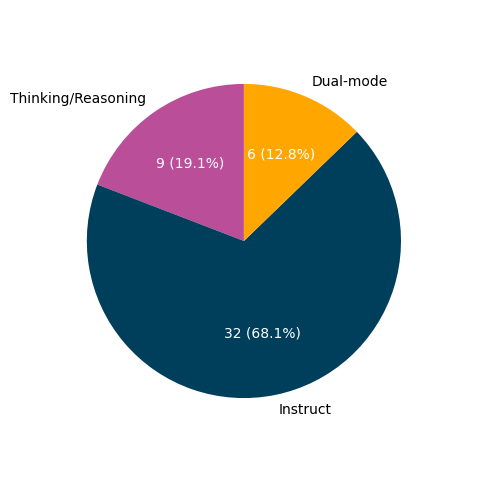

In [14]:
thinking_count = (before_split_filtered_df["is_thinking"] & ~before_split_filtered_df["supports_enable_thinking"]).sum()
instruct_count = (before_split_filtered_df["is_instruct"] & ~before_split_filtered_df["supports_enable_thinking"]).sum()
dual_mode_count = before_split_filtered_df["supports_enable_thinking"].sum()

mode_counts = pd.Series(
    [thinking_count, instruct_count, dual_mode_count],
    index=["Thinking/Reasoning", "Instruct", "Dual-mode"],
)

fig, ax = plt.subplots(figsize=(6, 6))
wedges, labels, autotexts = ax.pie(
    mode_counts,
    labels=mode_counts.index,
    autopct=lambda pct: f"{int(round(pct / 100 * mode_counts.sum()))} ({pct:.1f}%)",
    startangle=90,
    colors=["#bb4e99", "#003f5c", "#ffa600"],
    radius=0.85,
 )
ax.set_aspect("equal", adjustable="box")
plt.setp(autotexts, color="white")
fig.savefig(chart_dir / "pie-operating-mode.svg", format="svg", bbox_inches="tight")

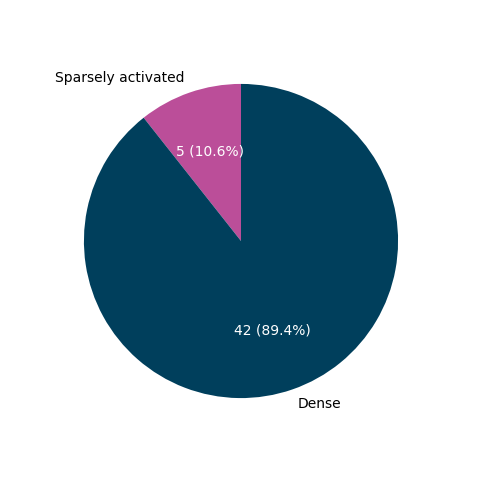

In [15]:
is_moe = (before_split_filtered_df["is_moe"]).sum()
is_dense = (len(before_split_filtered_df) - is_moe)

mode_counts = pd.Series(
    [is_moe, is_dense],
    index=["Sparsely activated", "Dense"],
)

fig, ax = plt.subplots(figsize=(6, 6))
wedges, labels, autotexts = ax.pie(
    mode_counts,
    labels=mode_counts.index,
    autopct=lambda pct: f"{int(round(pct / 100 * mode_counts.sum()))} ({pct:.1f}%)",
    startangle=90,
    colors=["#bb4e99", "#003f5c"],
    radius=0.85,
 )
ax.set_aspect("equal", adjustable="box")
plt.setp(autotexts, color="white")
fig.savefig(chart_dir / "pie-architectural-paradigm.svg", format="svg", bbox_inches="tight")

### 12. Visualization of model distribution over time by size category, after filtering.

The presence of both older and newer models across all categories is not affected by the selection process.

/tmp/ipykernel_3346231/3499624572.py:17: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  plot_df["category"] = pd.Categorical(plot_df["category"], categories=cat_order, ordered=True)


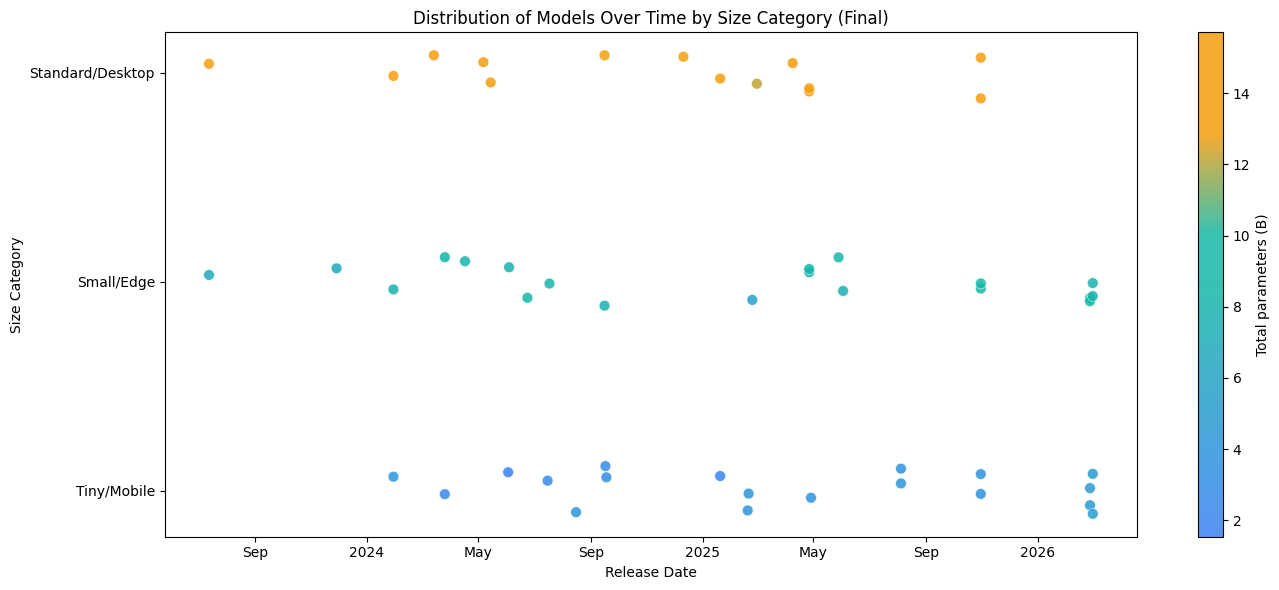

In [16]:
custom_cmap = LinearSegmentedColormap.from_list(
    "size_gradient",
    [
        (0, "#3B82F6"),
        (0.5, "#14B8A6"),
        (0.6, "#14B8A6"),
        (0.8, "#F59E0B"),
        (1, "#F59E0B"),
    ]
)

plot_df = filtered_df.copy()
plot_df["release_date"] = pd.to_datetime(plot_df["release_date"], errors="coerce")
plot_df = plot_df.dropna(subset=["release_date", "category"]).copy()

cat_order = ["Tiny/Mobile", "Small/Edge", "Standard/Desktop"]
plot_df["category"] = pd.Categorical(plot_df["category"], categories=cat_order, ordered=True)
plot_df = plot_df.dropna(subset=["category"])

y_codes = plot_df["category"].cat.codes.to_numpy()
rng = np.random.default_rng(42)
jitter = (rng.random(len(y_codes)) - 0.5) * 0.25
y_jitter = y_codes + jitter

fig, ax = plt.subplots(figsize=(14, 6))
sc = ax.scatter(
    plot_df["release_date"],
    y_jitter,
    c=plot_df["total_parameters"],
    cmap=custom_cmap,
    s=60,
    alpha=0.85,
    edgecolors="w",
    linewidth=0.4,
)

ax.set_yticks(range(len(cat_order)))
ax.set_yticklabels(cat_order)
ax.set_xlabel("Release Date")
ax.set_ylabel("Size Category")
ax.set_title("Distribution of Models Over Time by Size Category (Final)")

locator = mdates.AutoDateLocator()
formatter = mdates.ConciseDateFormatter(locator)
ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(formatter)

cbar = fig.colorbar(sc, ax=ax)
cbar.set_label("Total parameters (B)")

plt.tight_layout()
fig.savefig(chart_dir / "distribution-over-time-final.svg", format="svg", bbox_inches="tight")
plt.show()

### 13. Visualization of model distribution over time by size category, only instruct non-MoE models.

/tmp/ipykernel_3346231/1884720820.py:8: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  plot_df["category"] = pd.Categorical(plot_df["category"], categories=cat_order, ordered=True)


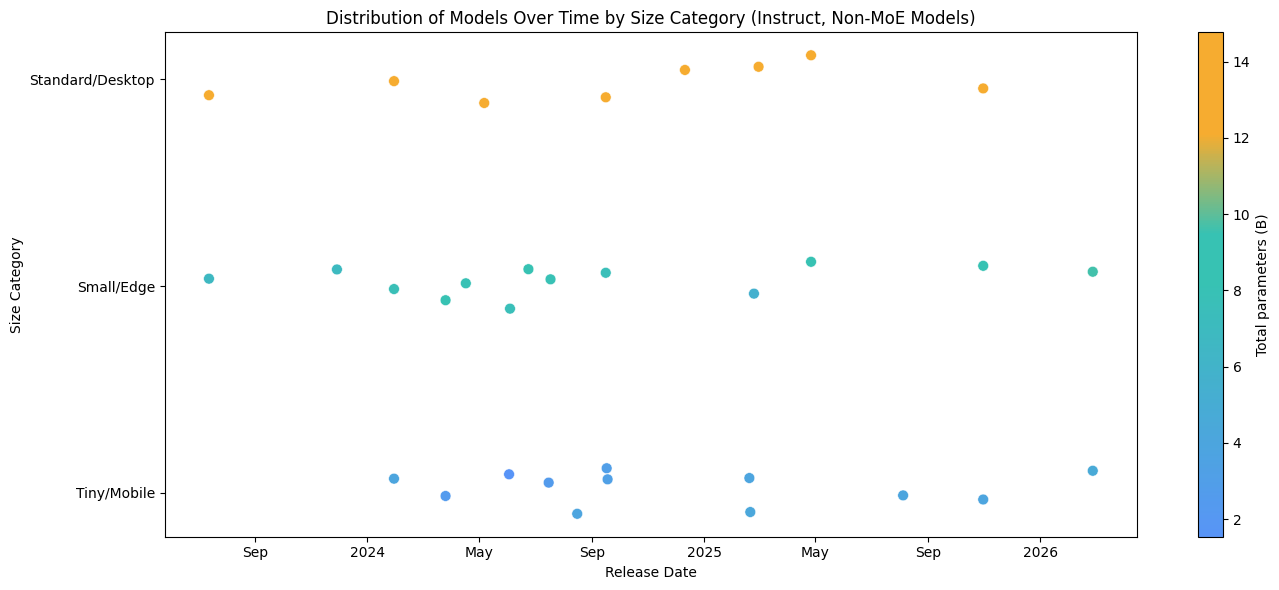

In [17]:
plot_df = filtered_df.copy()
plot_df = plot_df[plot_df["is_instruct"].isin([True])].copy()
plot_df = plot_df[plot_df["is_moe"].isin([False])].copy()
plot_df["release_date"] = pd.to_datetime(plot_df["release_date"], errors="coerce")
plot_df = plot_df.dropna(subset=["release_date", "category"]).copy()

cat_order = ["Tiny/Mobile", "Small/Edge", "Standard/Desktop"]
plot_df["category"] = pd.Categorical(plot_df["category"], categories=cat_order, ordered=True)
plot_df = plot_df.dropna(subset=["category"])

y_codes = plot_df["category"].cat.codes.to_numpy()
rng = np.random.default_rng(42)
jitter = (rng.random(len(y_codes)) - 0.5) * 0.25
y_jitter = y_codes + jitter

fig, ax = plt.subplots(figsize=(14, 6))
sc = ax.scatter(
    plot_df["release_date"],
    y_jitter,
    c=plot_df["total_parameters"],
    cmap=custom_cmap,
    s=60,
    alpha=0.85,
    edgecolors="w",
    linewidth=0.4,
)

ax.set_yticks(range(len(cat_order)))
ax.set_yticklabels(cat_order)
ax.set_xlabel("Release Date")
ax.set_ylabel("Size Category")
ax.set_title("Distribution of Models Over Time by Size Category (Instruct, Non-MoE Models)")

locator = mdates.AutoDateLocator()
formatter = mdates.ConciseDateFormatter(locator)
ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(formatter)

cbar = fig.colorbar(sc, ax=ax)
cbar.set_label("Total parameters (B)")

plt.tight_layout()
fig.savefig(chart_dir / "distribution-over-time-instruct-non-moe.svg", format="svg", bbox_inches="tight")
plt.show()

### 14. Visualization of model distribution over time by size category, only thinking non-MoE models.

/tmp/ipykernel_3346231/1968456114.py:8: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  plot_df["category"] = pd.Categorical(plot_df["category"], categories=cat_order, ordered=True)


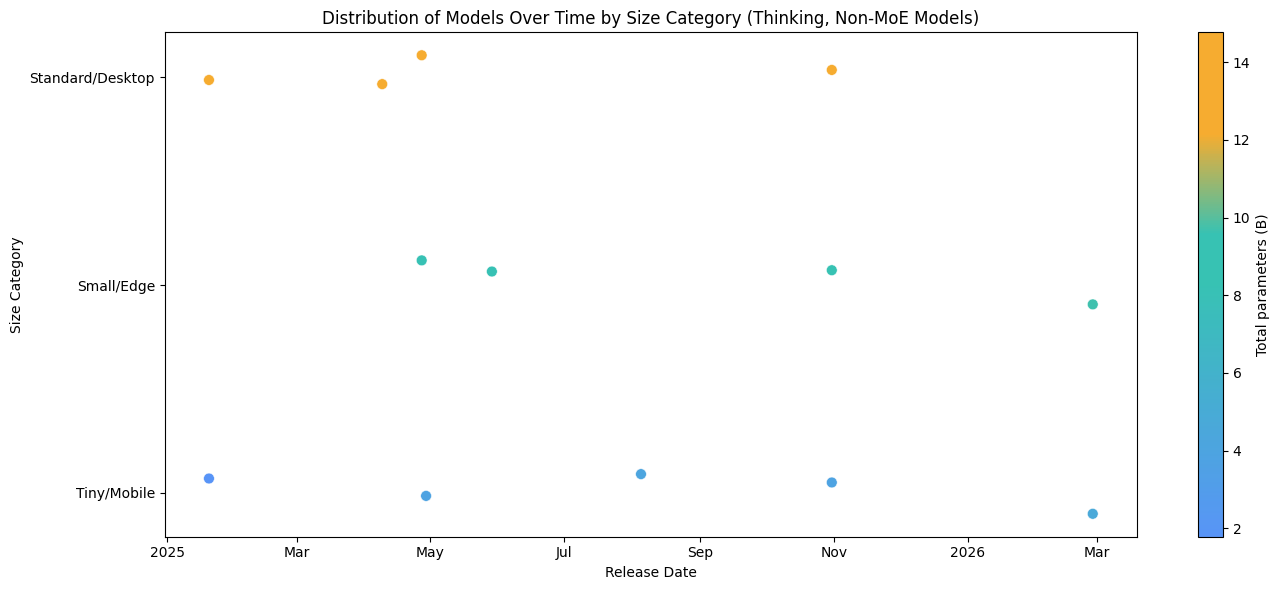

In [18]:
plot_df = filtered_df.copy()
plot_df = plot_df[plot_df["is_thinking"].isin([True])].copy()
plot_df = plot_df[plot_df["is_moe"].isin([False])].copy()
plot_df["release_date"] = pd.to_datetime(plot_df["release_date"], errors="coerce")
plot_df = plot_df.dropna(subset=["release_date", "category"]).copy()

cat_order = ["Tiny/Mobile", "Small/Edge", "Standard/Desktop"]
plot_df["category"] = pd.Categorical(plot_df["category"], categories=cat_order, ordered=True)
plot_df = plot_df.dropna(subset=["category"])

y_codes = plot_df["category"].cat.codes.to_numpy()
rng = np.random.default_rng(42)
jitter = (rng.random(len(y_codes)) - 0.5) * 0.25
y_jitter = y_codes + jitter

fig, ax = plt.subplots(figsize=(14, 6))
sc = ax.scatter(
    plot_df["release_date"],
    y_jitter,
    c=plot_df["total_parameters"],
    cmap=custom_cmap,
    s=60,
    alpha=0.85,
    edgecolors="w",
    linewidth=0.4,
)

ax.set_yticks(range(len(cat_order)))
ax.set_yticklabels(cat_order)
ax.set_xlabel("Release Date")
ax.set_ylabel("Size Category")
ax.set_title("Distribution of Models Over Time by Size Category (Thinking, Non-MoE Models)")

locator = mdates.AutoDateLocator()
formatter = mdates.ConciseDateFormatter(locator)
ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(formatter)

cbar = fig.colorbar(sc, ax=ax)
cbar.set_label("Total parameters (B)")

plt.tight_layout()
fig.savefig(chart_dir / "distribution-over-time-thinking-non-moe.svg", format="svg", bbox_inches="tight")
plt.show()

### 15. Visualization of model distribution over time by size category, only instruct MoE models.

/tmp/ipykernel_3346231/699287891.py:8: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  plot_df["category"] = pd.Categorical(plot_df["category"], categories=cat_order, ordered=True)


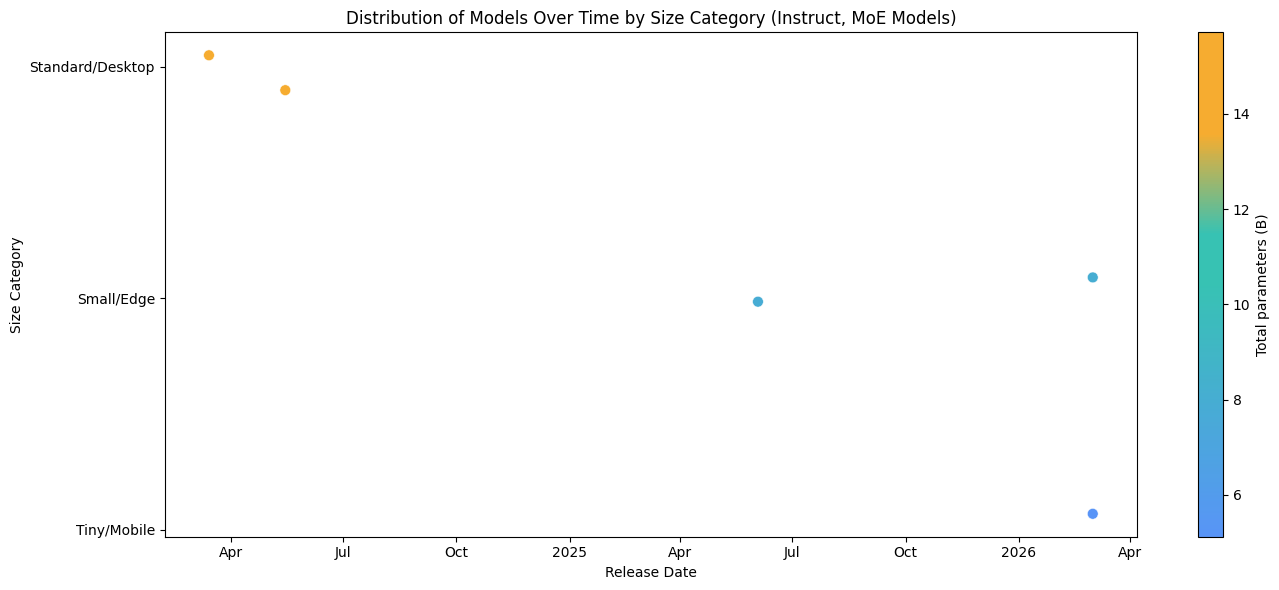

In [19]:
plot_df = filtered_df.copy()
plot_df = plot_df[plot_df["is_instruct"].isin([True])].copy()
plot_df = plot_df[plot_df["is_moe"].isin([True])].copy()
plot_df["release_date"] = pd.to_datetime(plot_df["release_date"], errors="coerce")
plot_df = plot_df.dropna(subset=["release_date", "category"]).copy()

cat_order = ["Tiny/Mobile", "Small/Edge", "Standard/Desktop"]
plot_df["category"] = pd.Categorical(plot_df["category"], categories=cat_order, ordered=True)
plot_df = plot_df.dropna(subset=["category"])

y_codes = plot_df["category"].cat.codes.to_numpy()
rng = np.random.default_rng(42)
jitter = (rng.random(len(y_codes)) - 0.5) * 0.25
y_jitter = y_codes + jitter

fig, ax = plt.subplots(figsize=(14, 6))
sc = ax.scatter(
    plot_df["release_date"],
    y_jitter,
    c=plot_df["total_parameters"],
    cmap=custom_cmap,
    s=60,
    alpha=0.85,
    edgecolors="w",
    linewidth=0.4,
)

ax.set_yticks(range(len(cat_order)))
ax.set_yticklabels(cat_order)
ax.set_xlabel("Release Date")
ax.set_ylabel("Size Category")
ax.set_title("Distribution of Models Over Time by Size Category (Instruct, MoE Models)")

locator = mdates.AutoDateLocator()
formatter = mdates.ConciseDateFormatter(locator)
ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(formatter)

cbar = fig.colorbar(sc, ax=ax)
cbar.set_label("Total parameters (B)")

plt.tight_layout()
fig.savefig(chart_dir / "distribution-over-time-instruct-moe.svg", format="svg", bbox_inches="tight")
plt.show()

### 16. Visualization of model distribution over time by size category, only thinking MoE models.

/tmp/ipykernel_3346231/393285645.py:13: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  plot_df["category"] = pd.Categorical(plot_df["category"], categories=cat_order, ordered=True)


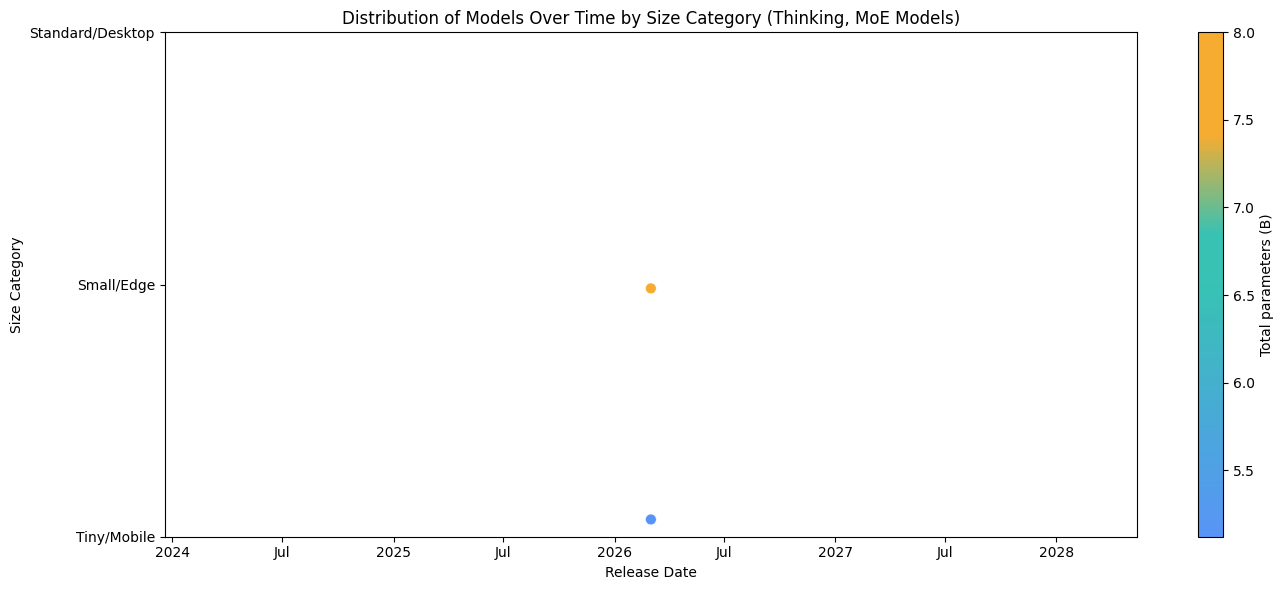

In [20]:
import numpy as np

import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plot_df = filtered_df.copy()
plot_df = plot_df[plot_df["is_thinking"].isin([True])].copy()
plot_df = plot_df[plot_df["is_moe"].isin([True])].copy()
plot_df["release_date"] = pd.to_datetime(plot_df["release_date"], errors="coerce")
plot_df = plot_df.dropna(subset=["release_date", "category"]).copy()

cat_order = ["Tiny/Mobile", "Small/Edge", "Standard/Desktop"]
plot_df["category"] = pd.Categorical(plot_df["category"], categories=cat_order, ordered=True)
plot_df = plot_df.dropna(subset=["category"])

y_codes = plot_df["category"].cat.codes.to_numpy()
rng = np.random.default_rng(42)
jitter = (rng.random(len(y_codes)) - 0.5) * 0.25
y_jitter = y_codes + jitter

fig, ax = plt.subplots(figsize=(14, 6))
sc = ax.scatter(
    plot_df["release_date"],
    y_jitter,
    c=plot_df["total_parameters"],
    cmap=custom_cmap,
    s=60,
    alpha=0.85,
    edgecolors="w",
    linewidth=0.4,
)

ax.set_yticks(range(len(cat_order)))
ax.set_yticklabels(cat_order)
ax.set_xlabel("Release Date")
ax.set_ylabel("Size Category")
ax.set_title("Distribution of Models Over Time by Size Category (Thinking, MoE Models)")

locator = mdates.AutoDateLocator()
formatter = mdates.ConciseDateFormatter(locator)
ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(formatter)

cbar = fig.colorbar(sc, ax=ax)
cbar.set_label("Total parameters (B)")

plt.tight_layout()
fig.savefig(chart_dir / "distribution-over-time-thinking-moe.svg", format="svg", bbox_inches="tight")
plt.show()